In [ ]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

In [50]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [51]:
df = pd.read_csv('/kaggle/input/datasets/rjmanoj/credit-card-customer-churn-prediction/Churn_Modelling.csv')

In [52]:
df.head()

,RowNumber,CustomerId,Surname,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
0,1,15634602,Hargrave,619,France,Female,42,2,0.00,1,1,1,101348.88,1
1,2,15647311,Hill,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0
2,3,15619304,Onio,502,France,Female,42,8,159660.80,3,1,0,113931.57,1
3,4,15701354,Boni,699,France,Female,39,1,0.00,2,0,0,93826.63,0
4,5,15737888,Mitchell,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,0


In [53]:
df.info()
#no not null values present
#data types are ok 

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 14 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   RowNumber        10000 non-null  int64  
 1   CustomerId       10000 non-null  int64  
 2   Surname          10000 non-null  object 
 3   CreditScore      10000 non-null  int64  
 4   Geography        10000 non-null  object 
 5   Gender           10000 non-null  object 
 6   Age              10000 non-null  int64  
 7   Tenure           10000 non-null  int64  
 8   Balance          10000 non-null  float64
 9   NumOfProducts    10000 non-null  int64  
 10  HasCrCard        10000 non-null  int64  
 11  IsActiveMember   10000 non-null  int64  
 12  EstimatedSalary  10000 non-null  float64
 13  Exited           10000 non-null  int64  
dtypes: float64(2), int64(9), object(3)
memory usage: 1.1+ MB


In [54]:
df.columns 

Index(['RowNumber', 'CustomerId', 'Surname', 'CreditScore', 'Geography',
       'Gender', 'Age', 'Tenure', 'Balance', 'NumOfProducts', 'HasCrCard',
       'IsActiveMember', 'EstimatedSalary', 'Exited'],
      dtype='object')

In [ ]:
# I will drop 1st 3 columns 
# RowNumber it is only showing the serial number ,CustomerId and Surname unique identifier no such need in Customer Churn Prediction
# Based on these 3 columns model can't tell if the person gonna discontinue or continue the bank service these three are irrelevent or noisy data
# It will slow down the model performance because it has misleading or irrelevant info which model dosen't need here 

In [55]:
df.drop(columns=['RowNumber', 'CustomerId', 'Surname'],inplace=True)

In [56]:
df

,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
0,619,France,Female,42,2,0.00,1,1,1,101348.88,1
1,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0
2,502,France,Female,42,8,159660.80,3,1,0,113931.57,1
3,699,France,Female,39,1,0.00,2,0,0,93826.63,0
4,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,0
...,...,...,...,...,...,...,...,...,...,...,...
9995,771,France,Male,39,5,0.00,2,1,0,96270.64,0
9996,516,France,Male,35,10,57369.61,1,1,1,101699.77,0
9997,709,France,Female,36,7,0.00,1,0,1,42085.58,1
9998,772,Germany,Male,42,3,75075.31,2,1,0,92888.52,1


In [57]:
df['Gender'].value_counts()

Gender
Male      5457
Female    4543
Name: count, dtype: int64

In [58]:
df['Geography'].value_counts()

Geography
France     5014
Germany    2509
Spain      2477
Name: count, dtype: int64

In [104]:
# Counts how many times each unique category appears in a categorical column.

# France     5014
# Germany    2509
# Spain      2477

# Why we check this before encoding:

# Identify categories — Neural Network or ML models don't understand text,
# so categorical columns (like Geography/Gender) need to be converted to numbers.
    
# Plan encoding method — knowing the number of unique categories helps decide between One-Hot Encoding vs Label Encoding.
    
# Check data imbalance — e.g., France has ~2x more data than Germany/Spain; imbalance can affect model learning.

# Catch typos/bad data — e.g., "france" vs "France" vs "Franc" would show up as separate categories if there's 
#a spelling error.

# Rule of thumb: Always run value_counts() on categorical columns before encoding.

In [59]:
df = pd.get_dummies(df,columns = ['Geography','Gender'],drop_first=True)

In [60]:
df

,CreditScore,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited,Geography_Germany,Geography_Spain,Gender_Male
0,619,42,2,0.00,1,1,1,101348.88,1,False,False,False
1,608,41,1,83807.86,1,0,1,112542.58,0,False,True,False
2,502,42,8,159660.80,3,1,0,113931.57,1,False,False,False
3,699,39,1,0.00,2,0,0,93826.63,0,False,False,False
4,850,43,2,125510.82,1,1,1,79084.10,0,False,True,False
...,...,...,...,...,...,...,...,...,...,...,...,...
9995,771,39,5,0.00,2,1,0,96270.64,0,False,False,True
9996,516,35,10,57369.61,1,1,1,101699.77,0,False,False,True
9997,709,36,7,0.00,1,0,1,42085.58,1,False,False,False
9998,772,42,3,75075.31,2,1,0,92888.52,1,True,False,True


In [61]:
df['Actual_y'] = df['Exited']

In [62]:
df

,CreditScore,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited,Geography_Germany,Geography_Spain,Gender_Male,Actual_y
0,619,42,2,0.00,1,1,1,101348.88,1,False,False,False,1
1,608,41,1,83807.86,1,0,1,112542.58,0,False,True,False,0
2,502,42,8,159660.80,3,1,0,113931.57,1,False,False,False,1
3,699,39,1,0.00,2,0,0,93826.63,0,False,False,False,0
4,850,43,2,125510.82,1,1,1,79084.10,0,False,True,False,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...
9995,771,39,5,0.00,2,1,0,96270.64,0,False,False,True,0
9996,516,35,10,57369.61,1,1,1,101699.77,0,False,False,True,0
9997,709,36,7,0.00,1,0,1,42085.58,1,False,False,False,1
9998,772,42,3,75075.31,2,1,0,92888.52,1,True,False,True,1


In [63]:
df.drop('Exited',axis = 1,inplace = True)

In [64]:
df

,CreditScore,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Geography_Germany,Geography_Spain,Gender_Male,Actual_y
0,619,42,2,0.00,1,1,1,101348.88,False,False,False,1
1,608,41,1,83807.86,1,0,1,112542.58,False,True,False,0
2,502,42,8,159660.80,3,1,0,113931.57,False,False,False,1
3,699,39,1,0.00,2,0,0,93826.63,False,False,False,0
4,850,43,2,125510.82,1,1,1,79084.10,False,True,False,0
...,...,...,...,...,...,...,...,...,...,...,...,...
9995,771,39,5,0.00,2,1,0,96270.64,False,False,True,0
9996,516,35,10,57369.61,1,1,1,101699.77,False,False,True,0
9997,709,36,7,0.00,1,0,1,42085.58,False,False,False,1
9998,772,42,3,75075.31,2,1,0,92888.52,True,False,True,1


In [65]:
df.shape

(10000, 12)

In [66]:
X = df.iloc[:,0:11]

In [67]:
y = df.iloc[:,-1]

In [68]:
from sklearn.model_selection import train_test_split

In [69]:
X_train,X_test,y_train,y_test = train_test_split(X,y,test_size=0.2,random_state=1)

In [70]:
from sklearn.preprocessing import StandardScaler

In [71]:
scaler = StandardScaler()

In [72]:
X_train_scaled = scaler.fit_transform(X_train)

In [73]:
X_test_scaled = scaler.transform(X_test)

In [94]:
import tensorflow 
from tensorflow import keras
from tensorflow.keras import Sequential
from tensorflow.keras.layers import Dense

In [95]:
model = Sequential()

In [96]:
model.add(Dense(11,activation='relu',input_dim = 11))
model.add(Dense(11,activation='relu'))
model.add(Dense(1,activation='sigmoid'))

/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [97]:
model.summary()

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_11 (Dense)                │ (None, 11)             │           132 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_12 (Dense)                │ (None, 11)             │           132 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_13 (Dense)                │ (None, 1)              │            12 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 276 (1.08 KB)

 Trainable params: 276 (1.08 KB)

 Non-trainable params: 0 (0.00 B)

In [98]:
model.compile(optimizer='Adam',loss='binary_crossentropy',metrics=['accuracy'])

In [79]:
model.fit(X_train_scaled,y_train,epochs=100,validation_split=0.2)

Epoch 1/100
200/200 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.6239 - loss: 0.6577 - val_accuracy: 0.7969 - val_loss: 0.5057
Epoch 2/100
200/200 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.7978 - loss: 0.4786 - val_accuracy: 0.7994 - val_loss: 0.4498
Epoch 3/100
200/200 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8030 - loss: 0.4389 - val_accuracy: 0.8050 - val_loss: 0.4239
Epoch 4/100
200/200 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8112 - loss: 0.4158 - val_accuracy: 0.8163 - val_loss: 0.4038
Epoch 5/100
200/200 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8277 - loss: 0.3980 - val_accuracy: 0.8388 - val_loss: 0.3864
Epoch 6/100
200/200 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.8381 - loss: 0.3827 - val_accuracy: 0.8475 - val_loss: 0.3701
Epoch 7/100
200/200 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.8431 - loss: 0.3715 - val_accuracy: 0.8487 - val_loss: 0.3608
Epoch 8/100
200/200 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.8516 - loss: 0.3634 - val_accu

In [80]:
prediction_by_model = model.predict(X_test_scaled)

63/63 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step


In [81]:
prediction_by_model

array([[0.02384099],
       [0.12154684],
       [0.0537614 ],
       ...,
       [0.01423768],
       [0.04538437],
       [0.42545438]], dtype=float32)

In [82]:
model.layers[0].get_weights()

[array([[ 0.12364879,  0.18582512, -0.10144646, -0.08163001,  0.12313922,
         -0.22835748,  0.02826801,  0.33483136,  0.07022473,  0.31798768,
         -0.20693736],
        [-0.93270886, -0.7425854 , -0.75778025, -0.06219302, -0.89963466,
          0.6645245 ,  0.3683565 , -0.4181749 ,  0.69771457,  0.06643453,
          0.29339308],
        [-0.10648666,  0.00461387,  0.18438573, -0.07832454, -0.1719734 ,
          0.5893597 ,  0.01643697, -0.58293843,  0.13689719,  0.0357766 ,
          0.06580008],
        [-0.14305617, -0.16974467,  0.10082757, -0.81502277, -0.267864  ,
          0.05422981, -0.07973289, -0.38244945, -0.31149882,  0.08580419,
         -0.71730447],
        [ 0.05225478, -0.02592461, -0.22388452, -1.093004  , -0.00797095,
          0.20673373,  1.0541506 ,  0.9828447 ,  0.13205169, -0.69464654,
          0.12715635],
        [-0.00488007, -0.0125804 ,  0.11176484, -0.05516462, -0.2699803 ,
          0.38832107,  0.00589449,  0.30717745,  0.08527974, -0.1936616

In [83]:
model.layers[1].get_weights()

[array([[ 0.49692565,  0.01159182, -0.8741088 ,  0.41000208,  0.5051902 ,
          0.28920135, -0.57955843, -0.3103889 ,  0.5296778 ,  0.1214958 ,
         -0.83926666],
        [-0.02156062,  0.5066563 , -0.4152674 , -0.31502187,  0.19273727,
          0.5294179 , -0.02385033,  0.30625004, -0.17997043, -0.24022126,
         -0.7057013 ],
        [ 0.6086706 ,  0.14537257, -0.4737288 ,  0.04070935,  0.44630736,
         -0.04645478,  0.06802545,  0.24437606, -0.15946637, -0.54061055,
         -0.6669432 ],
        [-0.4958909 , -0.12418509,  0.5701516 , -0.07780579, -0.7199522 ,
         -0.2605726 ,  0.61743695, -0.9225887 ,  0.6182496 ,  0.31007737,
          0.5185838 ],
        [ 0.10882037,  0.576027  , -0.64697206,  0.17747194,  0.10941187,
          0.05711482,  0.05275105,  0.2776455 , -0.10711862, -0.14552532,
         -0.65013343],
        [ 0.18980196,  0.3589317 ,  0.47734812, -0.58329725, -0.7911595 ,
          0.60394543,  0.14731082,  0.22859755, -0.2084669 ,  0.4152609

In [84]:
y_pred = np.where(prediction_by_model>0.5,1,0)

In [85]:
from sklearn.metrics import accuracy_score

In [86]:
accuracy_score(y_test,y_pred)

0.855

In [99]:
#Will store this data as history object to plot the graph 
history = model.fit(X_train_scaled,y_train,epochs=100,validation_split=0.2)

Epoch 1/100
200/200 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.7950 - loss: 0.5144 - val_accuracy: 0.8006 - val_loss: 0.4765
Epoch 2/100
200/200 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8047 - loss: 0.4564 - val_accuracy: 0.8081 - val_loss: 0.4413
Epoch 3/100
200/200 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.8142 - loss: 0.4309 - val_accuracy: 0.8194 - val_loss: 0.4245
Epoch 4/100
200/200 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8230 - loss: 0.4182 - val_accuracy: 0.8219 - val_loss: 0.4155
Epoch 5/100
200/200 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8284 - loss: 0.4106 - val_accuracy: 0.8244 - val_loss: 0.4091
Epoch 6/100
200/200 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.8325 - loss: 0.4035 - val_accuracy: 0.8288 - val_loss: 0.4026
Epoch 7/100
200/200 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.8372 - loss: 0.3960 - val_accuracy: 0.8306 - val_loss: 0.3959
Epoch 8/100
200/200 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8391 - loss: 0.3880 - val_accu

In [89]:
history.history
#now will get a history of key value pair dictionary 'accuracy':,'loss':,'val_accuracy':,'val_loss':

{'accuracy': [0.8732812404632568,
  0.8723437786102295,
  0.8725000023841858,
  0.8740624785423279,
  0.8728125095367432,
  0.8723437786102295,
  0.8731250166893005,
  0.8721874952316284,
  0.8739062547683716,
  0.8725000023841858,
  0.871874988079071,
  0.8731250166893005,
  0.8737499713897705,
  0.8735937476158142,
  0.874218761920929,
  0.8748437762260437,
  0.8734375238418579,
  0.8721874952316284,
  0.8739062547683716,
  0.875,
  0.874218761920929,
  0.8714062571525574,
  0.8729687333106995,
  0.8729687333106995,
  0.8723437786102295,
  0.8735937476158142,
  0.8726562261581421,
  0.8725000023841858,
  0.8740624785423279,
  0.8721874952316284,
  0.8737499713897705,
  0.8740624785423279,
  0.8728125095367432,
  0.8735937476158142,
  0.8721874952316284,
  0.8746874928474426,
  0.8728125095367432,
  0.8751562237739563,
  0.8735937476158142,
  0.8740624785423279,
  0.8734375238418579,
  0.8739062547683716,
  0.8729687333106995,
  0.874218761920929,
  0.8734375238418579,
  0.87453126907

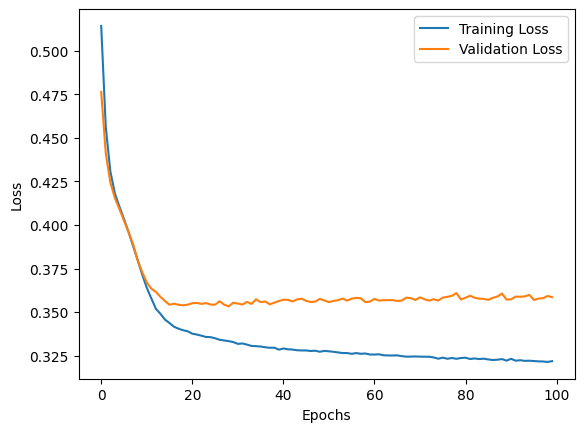

In [101]:
#'accuracy':,'loss':,'val_accuracy':,'val_loss':
plt.plot(history.history['loss'])
plt.plot(history.history['val_loss'])
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend(['Training Loss', 'Validation Loss'])
plt.show()

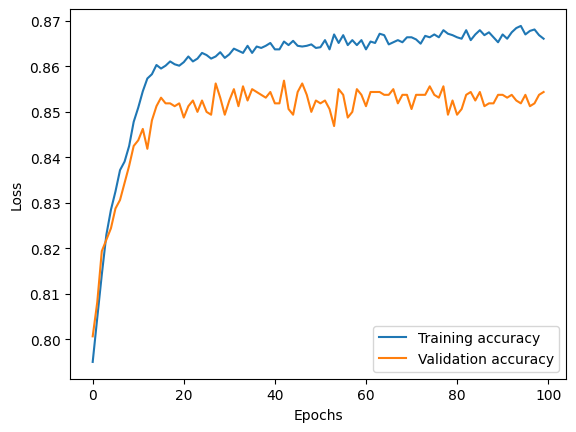

In [103]:
#'accuracy':,'loss':,'val_accuracy':,'val_loss':
plt.plot(history.history['accuracy'])
plt.plot(history.history['val_accuracy'])
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend(['Training accuracy', 'Validation accuracy'])
plt.show()